#ALEJANDRO MURILLO ZAPATA - SANTIAGO MORENO ORTIZ
#3223877
# TSH — Technology, Software & Hardware

### Análisis y calidad de datos mediante Python y Pandas

**Contexto del proyecto**

TSH es una plataforma empresarial de gestión inteligente de activos físicos que integra tecnología NFC e inteligencia artificial para mejorar el control, la identificación y el seguimiento de equipos dentro de una organización.

El sistema permite registrar activos, consultar sus ubicaciones, administrar mantenimientos y acceder a información técnica mediante etiquetas NFC.

Para este ejercicio se analizará un inventario ficticio de 15 activos tecnológicos, utilizando Python, Pandas y Matplotlib en Google Colab.

### Reglas de negocio

**RN-001 — Unicidad de etiquetas NFC**

Cada activo debe tener una etiqueta NFC única y ninguna etiqueta puede estar asociada simultáneamente a dos activos diferentes.

Esta regla permite identificar activos sin etiqueta y detectar asociaciones duplicadas que afectan la trazabilidad.

**RN-002 — Ubicación obligatoria del activo**

Todos los activos registrados deben contar con una ubicación válida que permita conocer dónde se encuentran dentro de la organización.

En TSH, la ubicación se organiza jerárquicamente por sede, bloque y salón o laboratorio. Para este ejercicio se verificará que el campo de ubicación no esté vacío.

### Objetivo del análisis

Utilizar Pandas para importar, inspeccionar, limpiar y analizar un inventario de 15 activos tecnológicos desde un archivo CSV, verificando el cumplimiento de las dos reglas de negocio.

### Preguntas de análisis

1. ¿Qué porcentaje de activos tiene una asociación NFC válida?
2. ¿Qué porcentaje de activos tiene una ubicación registrada?
3. ¿Cuántos activos cumplen ambas reglas de negocio?
4. ¿Qué inconsistencias deben corregirse para mejorar la calidad del inventario?

**Herramientas:** Python, Google Colab, Pandas, NumPy y Matplotlib.



### Presentación del análisis

Se presenta el proyecto TSH mediante un encabezado visual desarrollado con Matplotlib. Este identifica el sistema y el propósito del ejercicio: analizar los datos de activos físicos asociados a etiquetas NFC.

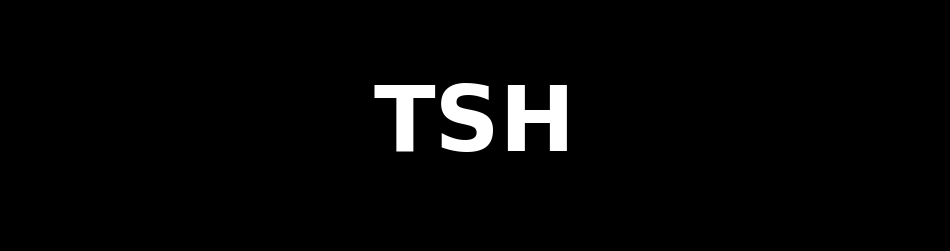

In [41]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3))

fig.patch.set_facecolor("black")
ax.set_facecolor("black")

ax.text(
    0.5, 0.5, "TSH",
    fontsize=65,
    fontweight="bold",
    color="white",
    ha="center",
    va="center"
)

ax.axis("off")
plt.show()

### 1. Importación del conjunto de datos

Se utiliza la biblioteca **Pandas** para importar un archivo CSV que contiene información de 15 activos tecnológicos.

El archivo incluye el identificador de cada activo, su nombre, etiqueta NFC, ubicación y cantidad de mantenimientos.

Los datos se almacenan en un DataFrame para facilitar su consulta y análisis.

In [33]:
import pandas as pd
import numpy as np
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    next(iter(uploaded)),
    index_col="id_activo"
)

display(df)

Saving inventario_tsh_nfc.csv to inventario_tsh_nfc (5).csv


,nombre,nfc,ubicacion,mantenimientos
id_activo,,,,
A001,Computador Dell,NFC001,Lab 101,2
A002,Proyector Epson,NFC002,Aula 202,1
A003,Impresora HP,NaN,Oficina 1,3
A004,Router Cisco,NFC004,NaN,0
A005,Portátil Lenovo,NFC002,Lab 103,2
A006,Monitor Samsung,NFC006,Lab 101,1
A007,Switch TP-Link,NFC007,Sala de redes,1
A008,Tablet Samsung,NaN,Aula 201,0
A009,Computador ASUS,NFC009,Lab 102,4


### 2. Estructuras de datos e indexación

Se identifican las principales estructuras utilizadas por Pandas: listas, diccionarios, Series, DataFrame e Index.

También se utilizan los métodos `loc` e `iloc` para consultar activos mediante su identificador o posición dentro del conjunto de datos.

In [34]:
lista = df["mantenimientos"].tolist()
diccionario = df.to_dict("list")
serie = df["mantenimientos"]
indice = df.index

display(serie)
display(df.loc[["A003"]])
display(df.iloc[[2]])
display(df.head())

,mantenimientos
id_activo,
A001,2
A002,1
A003,3
A004,0
A005,2
A006,1
A007,1
A008,0
A009,4


,nombre,nfc,ubicacion,mantenimientos
id_activo,,,,
A003,Impresora HP,NaN,Oficina 1,3


,nombre,nfc,ubicacion,mantenimientos
id_activo,,,,
A003,Impresora HP,NaN,Oficina 1,3


,nombre,nfc,ubicacion,mantenimientos
id_activo,,,,
A001,Computador Dell,NFC001,Lab 101,2
A002,Proyector Epson,NFC002,Aula 202,1
A003,Impresora HP,NaN,Oficina 1,3
A004,Router Cisco,NFC004,NaN,0
A005,Portátil Lenovo,NFC002,Lab 103,2


### 3. Lectura e inspección de datos

Se exporta el inventario a Excel y se vuelve a importar para comprobar la lectura de archivos.

Posteriormente, se utilizan los métodos `info()`, `describe()` e `isnull()` para identificar los tipos de datos, obtener estadísticas descriptivas y detectar información faltante.

In [35]:
df.to_excel("inventario_tsh.xlsx")

excel = pd.read_excel(
    "inventario_tsh.xlsx",
    index_col="id_activo"
)

display(excel.head())

df.info()
display(df.describe())
display(df.isnull().sum())

,nombre,nfc,ubicacion,mantenimientos
id_activo,,,,
A001,Computador Dell,NFC001,Lab 101,2
A002,Proyector Epson,NFC002,Aula 202,1
A003,Impresora HP,NaN,Oficina 1,3
A004,Router Cisco,NFC004,NaN,0
A005,Portátil Lenovo,NFC002,Lab 103,2


<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, A001 to A015
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   nombre          15 non-null     object
 1   nfc             12 non-null     object
 2   ubicacion       13 non-null     object
 3   mantenimientos  15 non-null     int64 
dtypes: int64(1), object(3)
memory usage: 1.1+ KB


,mantenimientos
count,15.000000
mean,1.800000
std,1.473577
min,0.000000
25%,1.000000
50%,2.000000
75%,2.500000
max,5.000000


,0
nombre,0
nfc,3
ubicacion,2
mantenimientos,0


### 4. Limpieza y comparación de datos

Se utilizan los métodos `dropna()` y `fillna()` para analizar diferentes alternativas de tratamiento de valores faltantes.

Con `dropna()` se eliminan temporalmente los registros incompletos, mientras que con `fillna()` se reemplazan las ubicaciones desconocidas por el valor "Sin registrar", conservando todos los activos.

Posteriormente, se comparan **la cantidad de filas y los valores nulos** antes y después de cada operación.

Esta comparación permite determinar qué método resulta más conveniente para el proyecto TSH, considerando que los activos no deben eliminarse del inventario únicamente por tener información incompleta.

In [42]:
sin_nulos = df.dropna()

limpio = df.fillna({
    "ubicacion": "Sin registrar"
})

comparacion = pd.DataFrame({
    "Filas": [
        len(df),
        len(sin_nulos),
        len(limpio)
    ],
    "Valores nulos": [
        df.isnull().sum().sum(),
        sin_nulos.isnull().sum().sum(),
        limpio.isnull().sum().sum()
    ]
}, index=["Original", "dropna()", "fillna()"])

display(comparacion)

,Filas,Valores nulos
Original,15,5
dropna(),10,0
fillna(),15,3


### 5. Validación de unicidad NFC — RN-001

Se verifica que cada activo tenga un identificador NFC registrado y que este no se encuentre asociado a otro activo.

Los registros se clasifican como válidos, sin NFC o duplicados. Esta clasificación permite identificar los problemas de vinculación presentes en el inventario.

In [37]:
limpio["estado_nfc"] = np.select(
    [
        limpio["nfc"].isna(),
        limpio["nfc"].duplicated(keep=False)
    ],
    ["Sin NFC", "Duplicado"],
    default="Válido"
)

display(limpio[["nombre", "nfc", "estado_nfc"]])

cumplen_nfc = (limpio["estado_nfc"] == "Válido").sum()
porcentaje_nfc = cumplen_nfc / len(limpio) * 100

print(f"Cumplimiento RN-001: {porcentaje_nfc:.2f}%")

,nombre,nfc,estado_nfc
id_activo,,,
A001,Computador Dell,NFC001,Válido
A002,Proyector Epson,NFC002,Duplicado
A003,Impresora HP,NaN,Sin NFC
A004,Router Cisco,NFC004,Válido
A005,Portátil Lenovo,NFC002,Duplicado
A006,Monitor Samsung,NFC006,Válido
A007,Switch TP-Link,NFC007,Válido
A008,Tablet Samsung,NaN,Sin NFC
A009,Computador ASUS,NFC009,Duplicado


Cumplimiento RN-001: 53.33%


### 6. Validación de ubicación — RN-002

Se comprueba que todos los activos tengan una ubicación registrada.

Los activos cuya ubicación es desconocida se clasifican como pendientes. Posteriormente, se calcula el porcentaje de cumplimiento de esta regla.

Esta validación permite identificar los equipos cuya localización debe ser confirmada por la organización.

In [38]:
limpio["estado_ubicacion"] = np.where(
    limpio["ubicacion"] == "Sin registrar",
    "Sin ubicación",
    "Válido"
)

display(
    limpio[["nombre", "ubicacion", "estado_ubicacion"]]
)

cumplen_ubicacion = (
    limpio["estado_ubicacion"] == "Válido"
).sum()

porcentaje_ubicacion = cumplen_ubicacion / len(limpio) * 100

print(f"Cumplimiento RN-002: {porcentaje_ubicacion:.2f}%")

,nombre,ubicacion,estado_ubicacion
id_activo,,,
A001,Computador Dell,Lab 101,Válido
A002,Proyector Epson,Aula 202,Válido
A003,Impresora HP,Oficina 1,Válido
A004,Router Cisco,Sin registrar,Sin ubicación
A005,Portátil Lenovo,Lab 103,Válido
A006,Monitor Samsung,Lab 101,Válido
A007,Switch TP-Link,Sala de redes,Válido
A008,Tablet Samsung,Aula 201,Válido
A009,Computador ASUS,Lab 102,Válido


Cumplimiento RN-002: 86.67%


### 7. Evaluación general de cumplimiento

Se combinan los resultados de ambas reglas de negocio para identificar los activos que cumplen simultáneamente con la unicidad NFC y el registro de ubicación.

Un activo se considera conforme únicamente cuando satisface las dos validaciones.

In [39]:
limpio["cumplimiento"] = np.where(
    (limpio["estado_nfc"] == "Válido") &
    (limpio["estado_ubicacion"] == "Válido"),
    "Cumple",
    "No cumple"
)

display(
    limpio[["nombre", "estado_nfc",
            "estado_ubicacion", "cumplimiento"]]
)

cumplen_ambas = (limpio["cumplimiento"] == "Cumple").sum()
porcentaje_general = cumplen_ambas / len(limpio) * 100

print(f"Cumplimiento general: {porcentaje_general:.2f}%")

,nombre,estado_nfc,estado_ubicacion,cumplimiento
id_activo,,,,
A001,Computador Dell,Válido,Válido,Cumple
A002,Proyector Epson,Duplicado,Válido,No cumple
A003,Impresora HP,Sin NFC,Válido,No cumple
A004,Router Cisco,Válido,Sin ubicación,No cumple
A005,Portátil Lenovo,Duplicado,Válido,No cumple
A006,Monitor Samsung,Válido,Válido,Cumple
A007,Switch TP-Link,Válido,Válido,Cumple
A008,Tablet Samsung,Sin NFC,Válido,No cumple
A009,Computador ASUS,Duplicado,Válido,No cumple


Cumplimiento general: 40.00%


### 8. Visualización de las reglas de negocio

Se utiliza Matplotlib para representar gráficamente los resultados obtenidos en las dos reglas de negocio.

- **RN-001 — Unicidad NFC:** muestra los activos con etiquetas válidas, duplicadas y faltantes.
- **RN-002 — Ubicación obligatoria:** muestra los activos que cuentan con una ubicación registrada y aquellos cuya ubicación es desconocida.
- **Comparación general:** presenta los porcentajes de cumplimiento de cada regla y el porcentaje de activos que cumplen ambas.

Estas visualizaciones permiten identificar las inconsistencias del inventario y comparar el cumplimiento de las reglas de negocio.

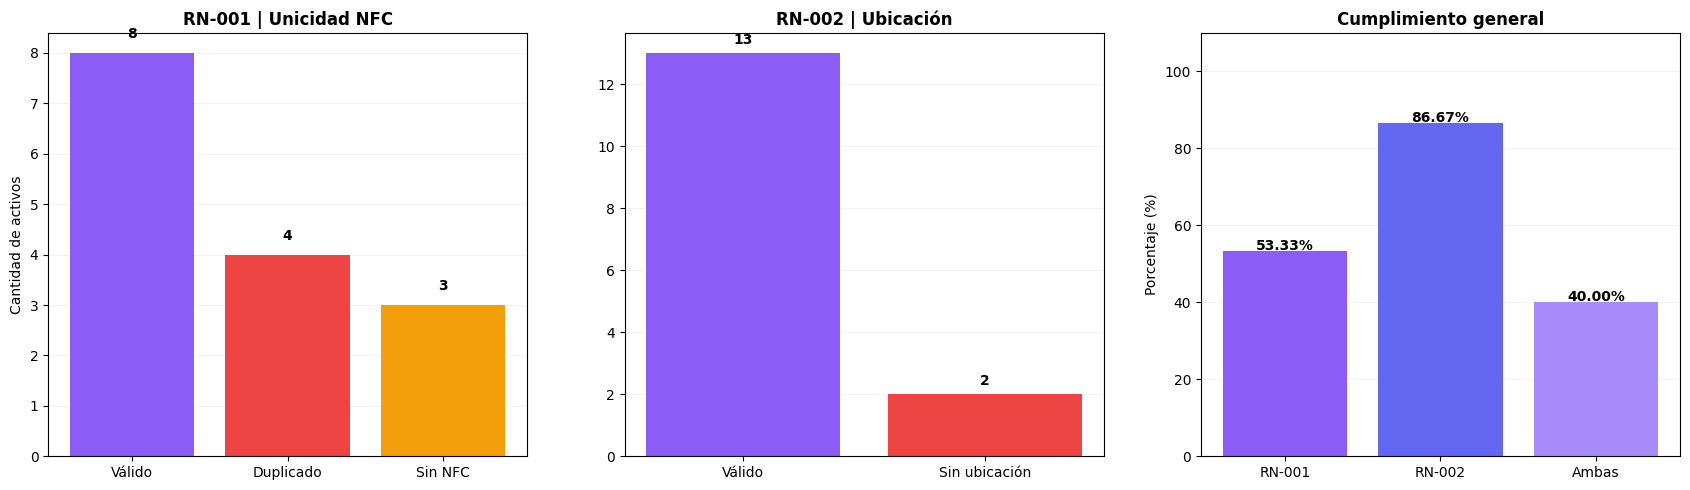

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

conteo_nfc = limpio["estado_nfc"].value_counts()

colores_nfc = {
    "Válido": "#8B5CF6",
    "Duplicado": "#EF4444",
    "Sin NFC": "#F59E0B"
}

axes[0].bar(
    conteo_nfc.index,
    conteo_nfc.values,
    color=[colores_nfc[x] for x in conteo_nfc.index]
)

axes[0].set_title("RN-001 | Unicidad NFC", fontweight="bold")
axes[0].set_ylabel("Cantidad de activos")

conteo_ubicacion = limpio["estado_ubicacion"].value_counts()

colores_ubicacion = {
    "Válido": "#8B5CF6",
    "Sin ubicación": "#EF4444"
}

axes[1].bar(
    conteo_ubicacion.index,
    conteo_ubicacion.values,
    color=[colores_ubicacion[x] for x in conteo_ubicacion.index]
)

axes[1].set_title("RN-002 | Ubicación", fontweight="bold")

reglas = ["RN-001", "RN-002", "Ambas"]
porcentajes = [
    porcentaje_nfc,
    porcentaje_ubicacion,
    porcentaje_general
]

axes[2].bar(
    reglas,
    porcentajes,
    color=["#8B5CF6", "#6366F1", "#A78BFA"]
)

axes[2].set_title("Cumplimiento general", fontweight="bold")
axes[2].set_ylabel("Porcentaje (%)")
axes[2].set_ylim(0, 110)

for ax in axes:
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for barra in ax.patches:
        valor = barra.get_height()

        ax.text(
            barra.get_x() + barra.get_width() / 2,
            valor + 0.3,
            f"{valor:.2f}%" if ax == axes[2] else f"{int(valor)}",
            ha="center",
            fontweight="bold"
        )

plt.tight_layout(w_pad=3)
plt.show()

### 9. Conclusiones del análisis de datos

El análisis realizado mediante **Python, Pandas y Matplotlib** permitió evaluar la calidad de la información de 15 activos tecnológicos registrados en el sistema TSH, aplicando dos reglas de negocio relacionadas con la trazabilidad de los equipos.

**RN-001 — Unicidad de etiquetas NFC**

- 8 activos tienen una asociación NFC válida.
- 4 activos presentan identificadores NFC duplicados.
- 3 activos no tienen una etiqueta NFC registrada.
- El porcentaje de cumplimiento es del **53,33 %**.

**RN-002 — Ubicación obligatoria**

- 13 activos tienen una ubicación registrada.
- 2 activos presentan información de ubicación faltante.
- El porcentaje de cumplimiento es del **86,67 %**.

**Cumplimiento general**

Al evaluar ambas reglas simultáneamente, se identificó que solamente **6 de los 15 activos (40 %)** cumplen con las dos condiciones establecidas.

Las gráficas elaboradas con Matplotlib permitieron visualizar las inconsistencias y evidenciar que la principal dificultad se encuentra en la asignación de etiquetas NFC, mientras que el registro de ubicaciones presenta un mayor nivel de cumplimiento.

### Decisiones y recomendaciones

1. Corregir las asociaciones NFC duplicadas para garantizar que cada etiqueta esté vinculada a un único activo.
2. Asignar etiquetas NFC a los activos que todavía no cuentan con una.
3. Verificar y completar las ubicaciones faltantes.
4. Realizar nuevas validaciones después de corregir los registros.

### Conclusión general

Este ejercicio demuestra cómo la analítica de datos puede apoyar la gestión inteligente de activos dentro de TSH. Mediante Pandas fue posible importar, inspeccionar, limpiar y validar los datos, mientras que Matplotlib facilitó la interpretación visual de los resultados.

**Se concluye que el inventario presenta un cumplimiento general del 40 %, por lo que es necesario mejorar la calidad de la información para garantizar una trazabilidad confiable de los activos.**

